In [3]:
import copy
class MapColoringCSP:   #(search.Problem)
    def __init__(self, variables, domains, constraints):
        """Construct a Map Coloring CSP problem."""
        self.variables = variables or list(domains.keys())  #List of variables or domains.keys() if variables is None
        self.domains = domains                              #Domains of all variables
        self.constraints = constraints                      #Constraints: dictionary of each variable with its neighbors 
        self.curr_domains = {v: list(self.domains[v]) for v in self.variables} #copy of domains - used in searching

    def assign(self, var, val, assignment):
        """Add {var: val} to assignment; Overwrite old value if any."""
        assignment[var] = val

    def unassign(self, var, assignment):
        """Remove {var: val} from assignment (for backtracking - reverting one assignment). 
        Note: USE assign method to CHANGE the VALUE of var."""
        if var in assignment:
            del assignment[var]

    def checkConstraint(self, var1, val1, var2, val2):
        """Validate a constraint: two neighbor variables, var1 and var2, should have different values"""
        return val1 != val2

    def nconflicts(self, var, val, assignment):
        """Return the number of conflicts var=val has with other variables."""
        def conflict(var2):
            return var2 in assignment and not self.checkConstraint(var, val, var2, assignment[var2])
        return sum(1 if conflict(v) else 0 for v in self.constraints[var])

    def suppose(self, var, value):
        """Return list of pruned assignments if assuming assignment var=value."""
        pruned = [(var, a) for a in self.curr_domains[var] if a != value]
        self.curr_domains[var] = [value]
        return pruned

    def prune(self, var, value, pruned):
        """Remove value from the domain of var and add such a pair to pruned list."""
        self.curr_domains[var].remove(value)
        if pruned is not None:
            pruned.append((var, value))

    def choices(self, var):
        """Return all values for var that are still available."""
        return (self.curr_domains or self.domains)[var]

    def restore(self, pruned):
        """Undo a previous supposition (restore domains of affected variables)."""
        for B, b in pruned:
            self.curr_domains[B].append(b)

In [10]:
# CSP Backtracking Search
import random

# Variable ordering
def select_unassigned_variable(csp, assignment):
    """The default variable order: Return the first unassigned variable."""
    return ([var for var in csp.variables if var not in assignment])[0]

# Value ordering
def order_domain_values(csp, var, assignment):
    """The default value order: return all possible values of var in its domain."""
    return csp.choices(var)

# Default filtering heuristic: No filtering
def no_filtering(csp, var, value, assignment, pruned):
    return True

# TODO: Filtering 1: Forward Checking (One Time Look-Ahead)
def forward_checking(csp, var, value, assignment, pruned):
    """Filtering 1: Prune neighbor values inconsistent with var=value."""
    # TODO: For a neighbor B of var in the constraint graph:
    for B in csp.constraints[var]:
        # TODO: If it hasn't been assigned a value (not in assignment):
        if B not in assignment:
            # TODO: For a value valB in the current domain of B: 
            for valB in csp.curr_domains[B][:]:
                # TODO: If the constraint of var and B is violated (use checkConstraint):
                if not csp.checkConstraint(var, value, B, valB):
                    # TODO: Prune such value valB from the domain of B
                    csp.prune(B, valB, pruned)
            # TODO: If domain of the neighbor is empty, return False
            if not csp.curr_domains[B]:
                return False
    # return True for completing the filtering step
    return True

def arc_consistency(csp, var, value, assignment, pruned): 
    """Filtering 2: Maintain arc consistency if assigns var=val""" 
    # Hint: you need to check the constraints for any binary constraint related to variable var 
    # and its neighbors and repeat the checking for other related constraints until either 
    # a variable has an empty domain (failure) or no more values can be pruned from the 
    # domain of any variables. 
    queue = []
    for X in csp.constraints[var]:
        queue.append((X, var)) 
    while queue:
        Xi, Xj = queue.pop(0)
        updated = False
        
        for x in csp.curr_domains[Xi][:]:
            for y in csp.curr_domains[Xj]:
                if not any(csp.checkConstraint(Xi, x, Xj, y)):
                    csp.prune(Xi, x, pruned)
                    updated = True
            if updated:
                if not csp.curr_domains[Xi]:
                    return False
                for Xk in csp.constraints[Xi]:
                    if Xk != Xj and Xk not in assignment:
                        queue.append((Xk, Xi))   
    return True

# TODO: The main backtracking search algorithm
def backtracking_search(csp, filtering=no_filtering, assignment=None):
    """Implement backtracking search with optional filtering heuristic."""
    if (assignment is None):                                # Initialize assignment if None
        assignment = {}
    if len(assignment) == len(csp.variables):               # If solution completes, return it
        return assignment
    var = select_unassigned_variable(csp, assignment)       # Select one unassigned variable
    for value in order_domain_values(csp, var, assignment): # For each value in the domain of var
        # TODO: If there are no conflicts (use csp.nconflicts method): 
        if csp.nconflicts(var, value, assignment) == 0:
            # TODO: Assign that value to var (use csp.assign method)
            csp.assign(var, value, assignment)
            # TODO: pruned = Get the list of pruned values of that var (use csp.suppose method)
            pruned = csp.suppose(var, value)
            if filtering(csp, var, value, assignment, pruned):      # Use filtering to validate all constraints
                # TODO: solution = Call backtracking_search recursively to fill remaining variables
                solution = backtracking_search(csp, filtering, assignment)
                # TODO: If solution exists, return it
                if solution is not None:
                    return solution
            # TODO: Restore the domain of the variable var (use csp.restore method)
            csp.restore(pruned)
    # TODO: Revert the assignment of variable var (use csp.unassign method)
    csp.unassign(var, assignment)
    return None # Failed - no solution

In [11]:
# Define the variables for the Australian states
variables = ["WA", "NT", "Q", "NSW", "V", "SA", "T"]
# Define the domains for each variable
domains = {v: ["Red", "Green", "Blue", "Yellow"] for v in variables}
# Define the constraints of the Australia problem
#   Each variable maps to a list of the neighbor variables that should have different colors
constraints = {   'WA': ['NT', 'SA'],
                  'SA': ['WA', 'NT', 'Q', 'NSW', 'V'],
                  'NT': ['WA', 'SA', 'Q'],
                  'Q': ['NT', 'SA', 'NSW'],
                  'NSW': ['Q', 'SA', 'V'],
                  'V': ['SA', 'NSW'],
                  'T': []
                }

# Define the Australia map coloring problem
australia_csp = MapColoringCSP(variables, domains, constraints)

# Run backtracking search on Australia CSP with/without filtering
solution = backtracking_search(australia_csp)
solution = backtracking_search(australia_csp, filtering = forward_checking)
print(solution)

{'WA': 'Red', 'NT': 'Green', 'Q': 'Red', 'NSW': 'Green', 'V': 'Red', 'SA': 'Blue', 'T': 'Red'}


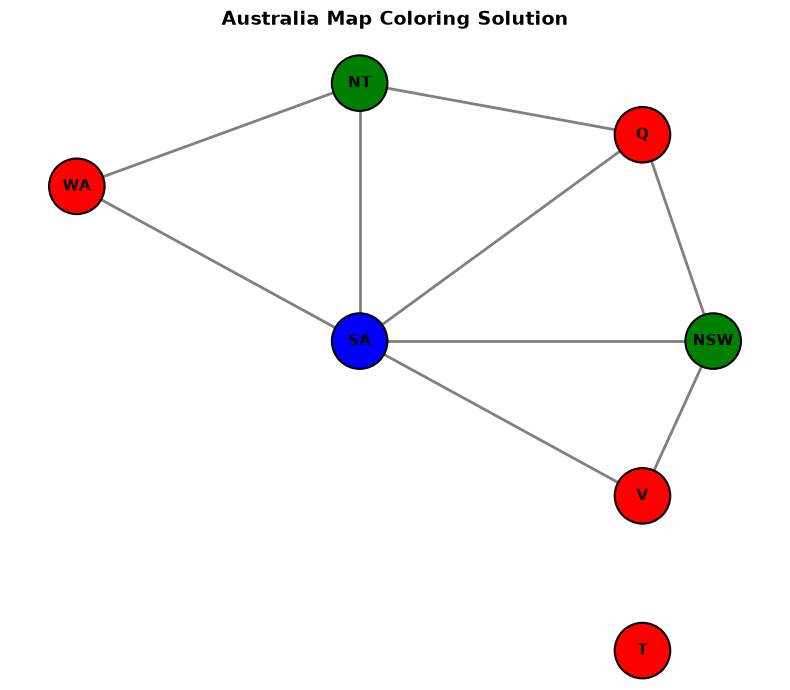

In [12]:
import matplotlib.pyplot as plt
import networkx as nx

def plot_map_solution(solution, constraints, pos=None):
    """Plots the map coloring solution as a colored network graph."""
    if not solution:
        print("No solution found to plot.")
        return

    # Create a NetworkX graph from the constraints dictionary
    G = nx.Graph()
    
    # Add nodes and edges based on adjacency
    for node, neighbors in constraints.items():
        G.add_node(node)
        for neighbor in neighbors:
            G.add_edge(node, neighbor)

    # If no explicit positions for the nodes, use networkx layout
    if pos is None:
        pos = nx.spring_layout(G, k=0.15)   #k=0.15

    # Extract node colors dynamically matching the CSP solver output
    node_colors = [solution[node].lower() for node in G.nodes()]

    # Setup the plot figure
    plt.figure(figsize=(8, 7))
    plt.title("Australia Map Coloring Solution", fontsize=14, fontweight='bold')

    # Draw nodes, edges, and labels
    nx.draw_networkx_nodes(G, pos, node_size=1600, node_color=node_colors, edgecolors='black', linewidths=1.5)
    nx.draw_networkx_edges(G, pos, width=2.0, edge_color='gray')
    nx.draw_networkx_labels(G, pos, font_size=11, font_weight='bold', font_color='black')

    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Define coordinates for Australian states/territories for realistic layout
pos = {
    "WA":  (1, 4),
    "NT":  (3, 5),
    "SA":  (3, 2.5),
    "Q":   (5, 4.5),
    "NSW": (5.5, 2.5),
    "V":   (5, 1),
    "T":   (5, -0.5)  # Tasmania placed below Victoria
}
# Generate the visualization for the Australia Map Coloring
plot_map_solution(solution, constraints, pos)